In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(
    "customs_features.csv",
    parse_dates=["entry_date", "accepted_date", "release_date"],
    dtype={"hs_code": str},
)
df.shape 

(4746, 35)

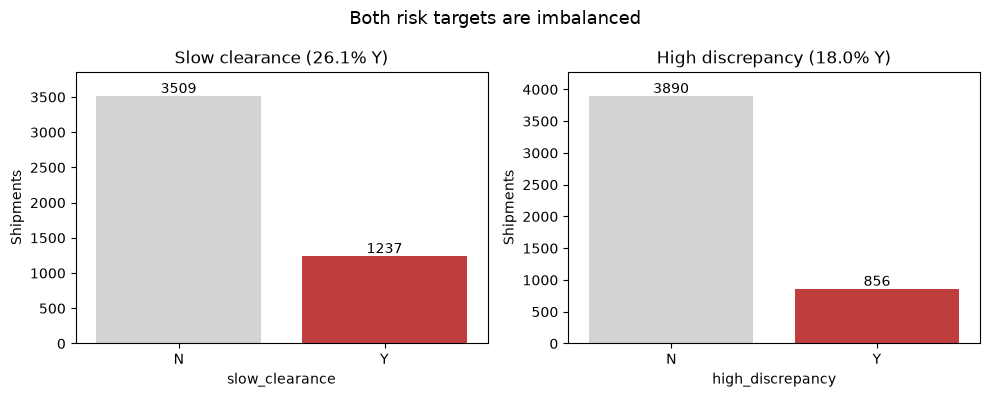

In [3]:
# CHART 1: Target balance
# Question: how common is each risk outcome, and what base rate must a model beat?
# Method: count of N and Y for slow_clearance and high_discrepancy, side by side

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=df, x='slow_clearance', ax=axes[0], order=['N', 'Y'],
              hue='slow_clearance', hue_order=['N', 'Y'],
              palette={'N': 'lightgrey', 'Y': 'tab:red'}, legend=False)

sns.countplot(data=df, x='high_discrepancy', ax=axes[1], order=['N', 'Y'],
              hue='high_discrepancy', hue_order=['N', 'Y'],
              palette={'N': 'lightgrey', 'Y': 'tab:red'}, legend=False)

axes[0].set_title("Slow clearance (26.1% Y)")
axes[0].set_xlabel("slow_clearance")
axes[0].set_ylabel("Shipments")

axes[1].set_title("High discrepancy (18.0% Y)")
axes[1].set_xlabel("high_discrepancy")
axes[1].set_ylabel("Shipments")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container)
    ax.margins(y=0.1)     

fig.suptitle("Both risk targets are imbalanced", fontsize=13)
plt.tight_layout()
plt.savefig("images/01_target_balance.png", dpi=150, bbox_inches="tight")
plt.show()


In [4]:
df['gap_pct']

0       0.021145
1       0.040518
2      -0.034004
3      -0.037384
4      -0.040090
          ...   
4741    0.309286
4742    0.031111
4743   -0.029666
4744   -0.001118
4745    0.500000
Name: gap_pct, Length: 4746, dtype: float64

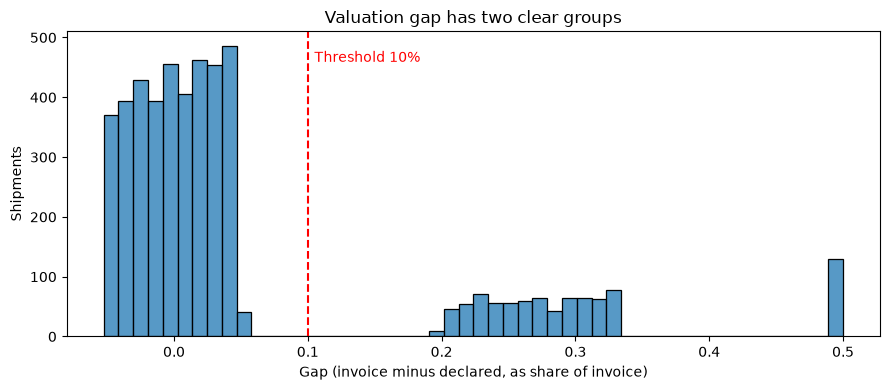

In [5]:
# CHART 2: Distribution of the valuation gap
# Question: do declared and invoice values split into distinct groups, and does a 10% threshold separate them?
# Method: histogram of gap_pct = (invoice - declared) / invoice, with the threshold drawn in

plt.figure(figsize=(9, 4))

sns.histplot(data=df, x="gap_pct", bins=50, color="tab:blue")
plt.axvline(0.10, linestyle="--", color="red")
plt.text(0.105, plt.ylim()[1] * 0.9, "Threshold 10%", color="red")

plt.title("Valuation gap has two clear groups")
plt.xlabel("Gap (invoice minus declared, as share of invoice)")
plt.ylabel("Shipments")

plt.tight_layout()
plt.savefig("images/02_gap_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
(df["gap_pct"].round(3) == 0.5).sum()

np.int64(129)

In [7]:
df.groupby(df["gap_pct"].round(3) == 0.5)["slow_clearance"].value_counts(normalize=True)

gap_pct  slow_clearance
False    N                 0.739658
         Y                 0.260342
True     N                 0.728682
         Y                 0.271318
Name: proportion, dtype: float64

In [8]:
# CHART 3: Slow rate by port
# Question: do some ports clear shipments slowly more often than others?
# Method: share of shipments with slow_clearance == "Y" per port, sorted high to low

port_rates = (
    df.assign(slow_flag=df["slow_clearance"] == "Y")
      .groupby("port_of_entry")
      .agg(rows=("shipment_id", "count"), slow_rate=("slow_flag", "mean"))
      .sort_values("slow_rate", ascending=False)
      .reset_index()
)
port_rates

,port_of_entry,rows,slow_rate
0,ALEXANDRIA,701,0.335235
1,MOMBASA,719,0.307371
2,LAGOS,701,0.306705
3,CASABLANCA,743,0.301480
4,MOMBASA ICD,231,0.207792
5,DURBAN,255,0.196078
6,TEMA,258,0.193798
7,DAR ES SALAAM,227,0.189427
8,PORT ELIZABETH,239,0.188285
9,NAIROBI,203,0.182266


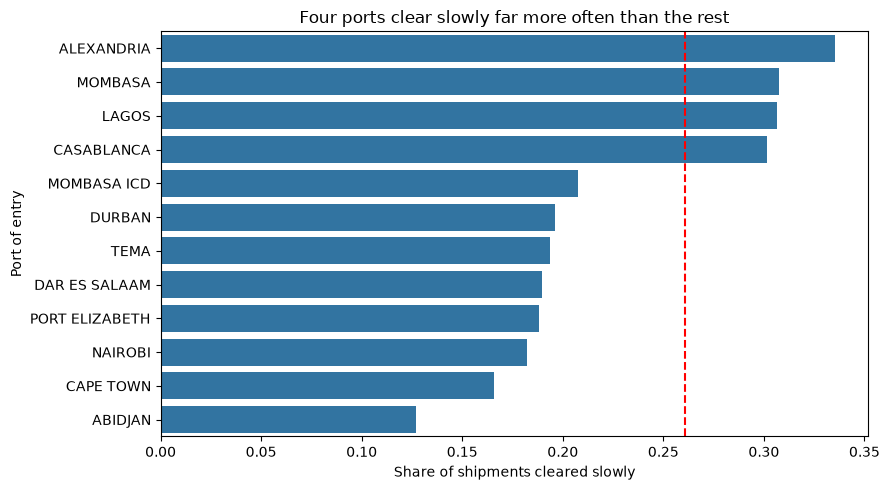

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(data=port_rates, x="slow_rate", y="port_of_entry", color="tab:blue")
plt.axvline(0.261, linestyle="--", color="red")

plt.title('Four ports clear slowly far more often than the rest')
plt.xlabel("Share of shipments cleared slowly")
plt.ylabel("Port of entry")

plt.tight_layout()
plt.savefig("images/03_slow_rate_by_port.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# CHART FOUR
# CHART 4: Slow rate by broker, HS section and country of origin
# Question: which brokers, product sections and origins are linked to slow clearance?
# Method: reusable function plot_slow_rate(); red line = overall rate (26.1%)

df.columns

Index(['shipment_id', 'entry_no', 'hs_code', 'product_desc', 'supplier',
       'country_origin', 'country_destination', 'declared_value_usd',
       'invoice_value_usd', 'weight_kg', 'volume_m3', 'broker',
       'port_of_entry', 'entry_date', 'accepted_date', 'release_date',
       'duty_amount_usd', 'tax_amount_usd', 'broker_fee_usd', 'incoterm',
       'license_required', 'license_obtained', 'fta_claimed',
       'restricted_party_pass', 'container_number', 'slow_clearance',
       'hs_chapter', 'hs_section', 'entry_day_of_week', 'entry_month',
       'entry_is_weekend', 'license_missing', 'gap_pct', 'high_discrepancy',
       'hs_section_name'],
      dtype='str')

In [11]:
def plot_slow_rate(column, title, filename, height=5):
    rates = (
        df.assign(slow_flag=df["slow_clearance"] == "Y")
          .groupby(column)
          .agg(rows=("shipment_id", "count"), slow_rate=("slow_flag", "mean"))
          .sort_values("slow_rate", ascending=False)
          .reset_index()
    )

    plt.figure(figsize=(9, height))
    sns.barplot(data=rates, x="slow_rate", y=column, color="tab:blue")
    plt.axvline(0.261, linestyle="--", color="red")

    plt.title(title)
    plt.xlabel("Share of shipments cleared slowly")
    plt.ylabel("___")

    plt.tight_layout()
    plt.savefig(f"images/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

    return rates

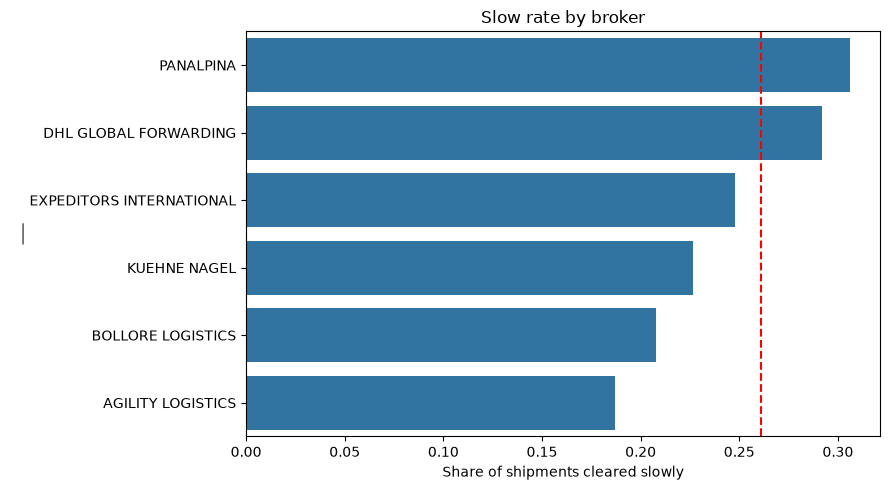

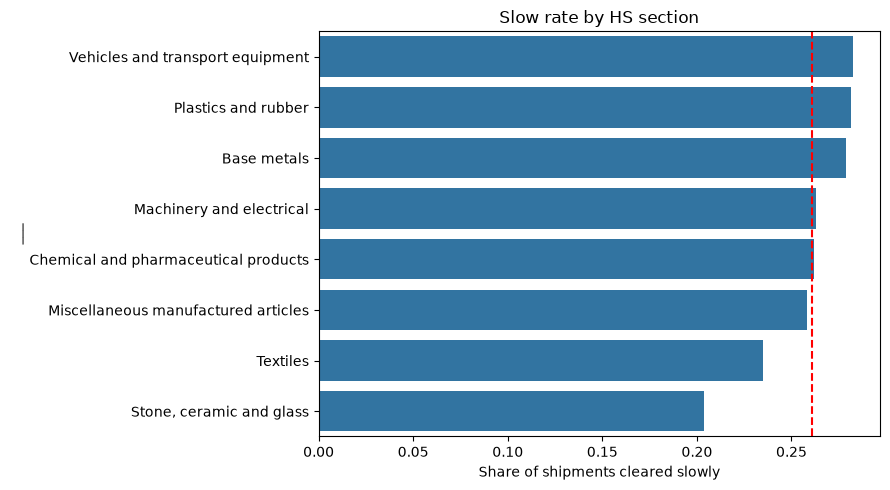

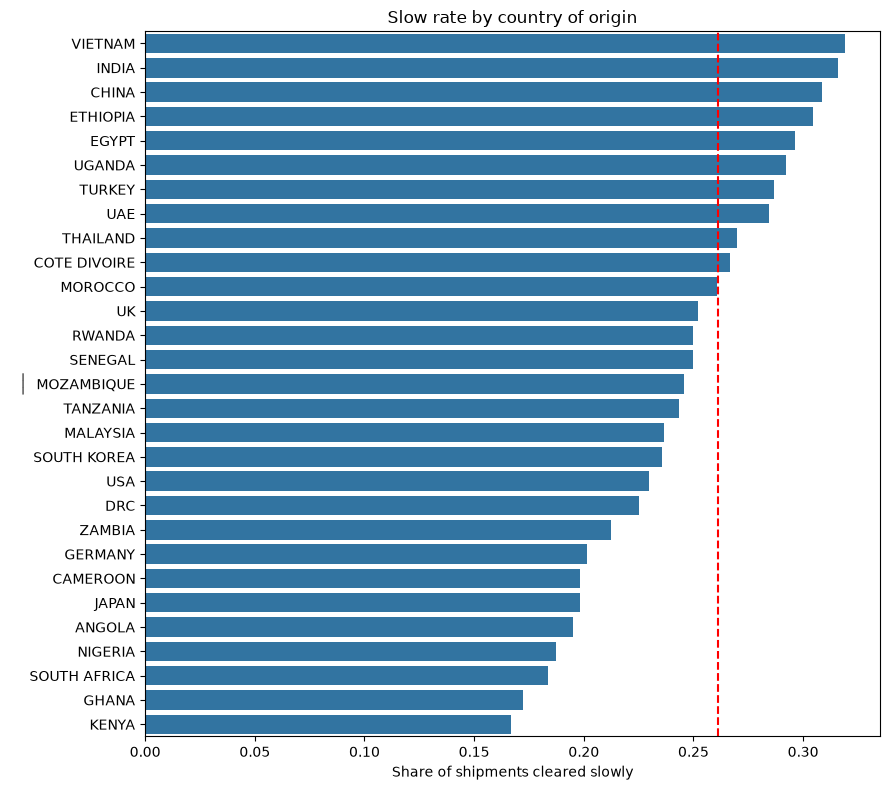

In [12]:
broker_rates = plot_slow_rate("broker", "Slow rate by broker", "04a_slow_rate_by_broker.png")
section_rates = plot_slow_rate("hs_section_name", "Slow rate by HS section", "04b_slow_rate_by_section.png")
origin_rates = plot_slow_rate("country_origin", "Slow rate by country of origin", "04c_slow_rate_by_origin.png", height=8)

In [13]:
df["country_origin"].nunique()

29

In [14]:
df["country_destination"].value_counts().to_string()

'country_destination\nSOUTH AFRICA    815\nTANZANIA        812\nGHANA           799\nUGANDA          797\nKENYA           796\nNIGERIA         727'

In [15]:
# CHART 5: High discrepancy rate by broker, HS section, supplier and origin
# Question: which groups are linked to a large gap between declared and invoice value?
# Method: same function generalised to any target (plot_rate); red line = overall rate (18.0%)

def plot_rate(column, target, title, filename, height=5):
    overall = (df[target] == "Y").mean()

    rates = (
        df.assign(flag=df[target] == "Y")
          .groupby(column)
          .agg(rows=("shipment_id", "count"), rate=("flag", "mean"))
          .sort_values("rate", ascending=False)
          .reset_index()
    )

    plt.figure(figsize=(9, height))
    sns.barplot(data=rates, x="rate", y=column, color="tab:blue")
    plt.axvline(overall, linestyle="--", color="red")

    plt.title(title)
    plt.xlabel(f"Share of shipments flagged ({target})")
    plt.ylabel("")

    plt.tight_layout()
    plt.savefig(f"images/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

    return rates

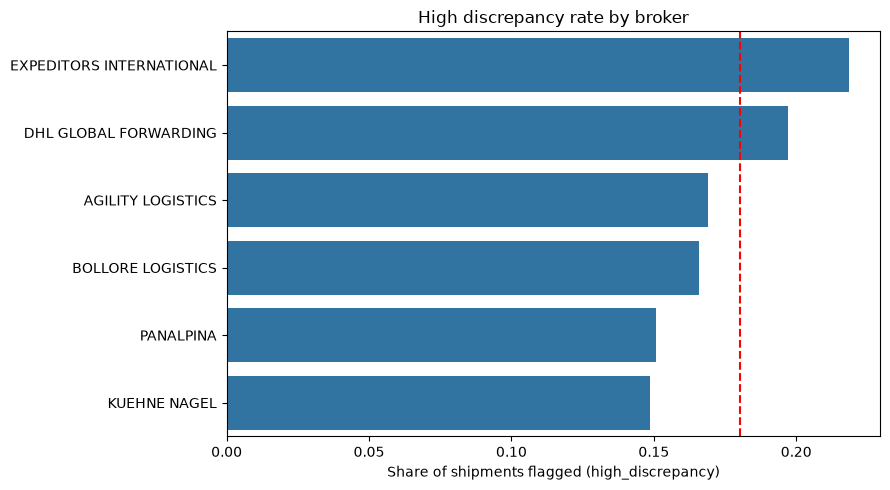

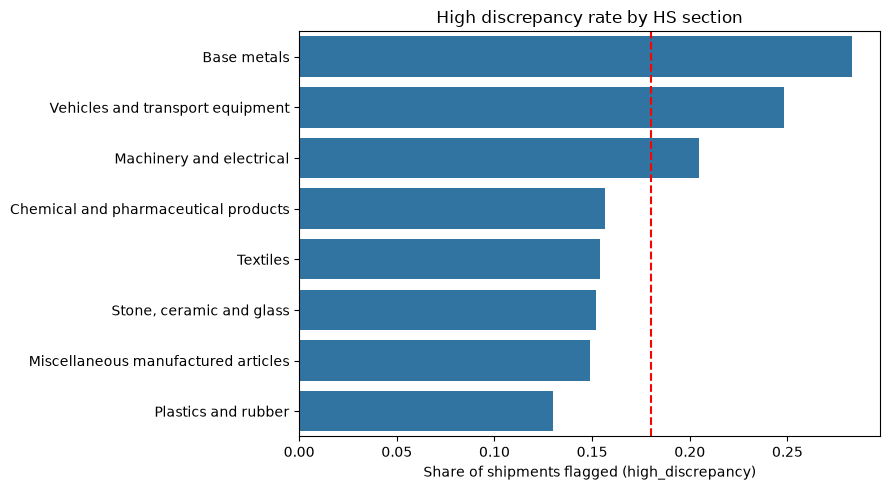

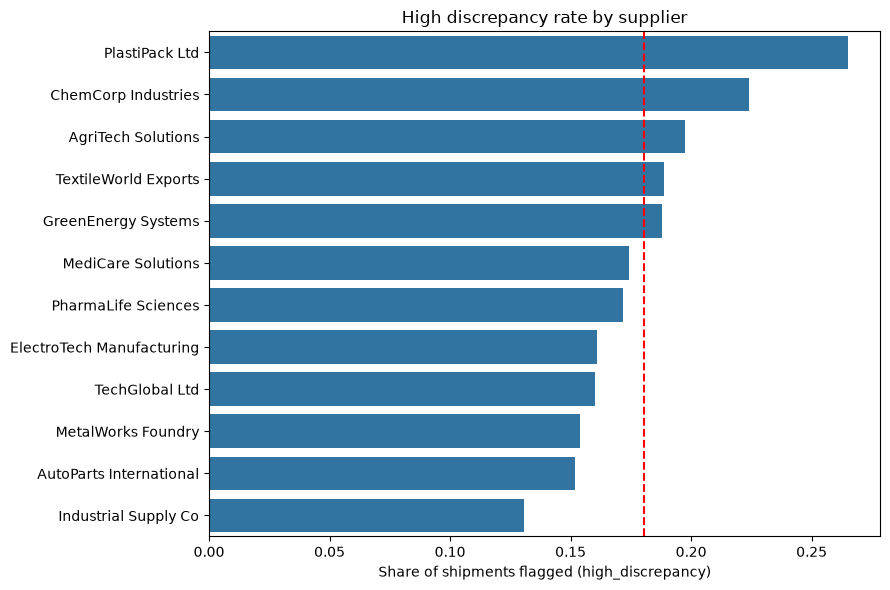

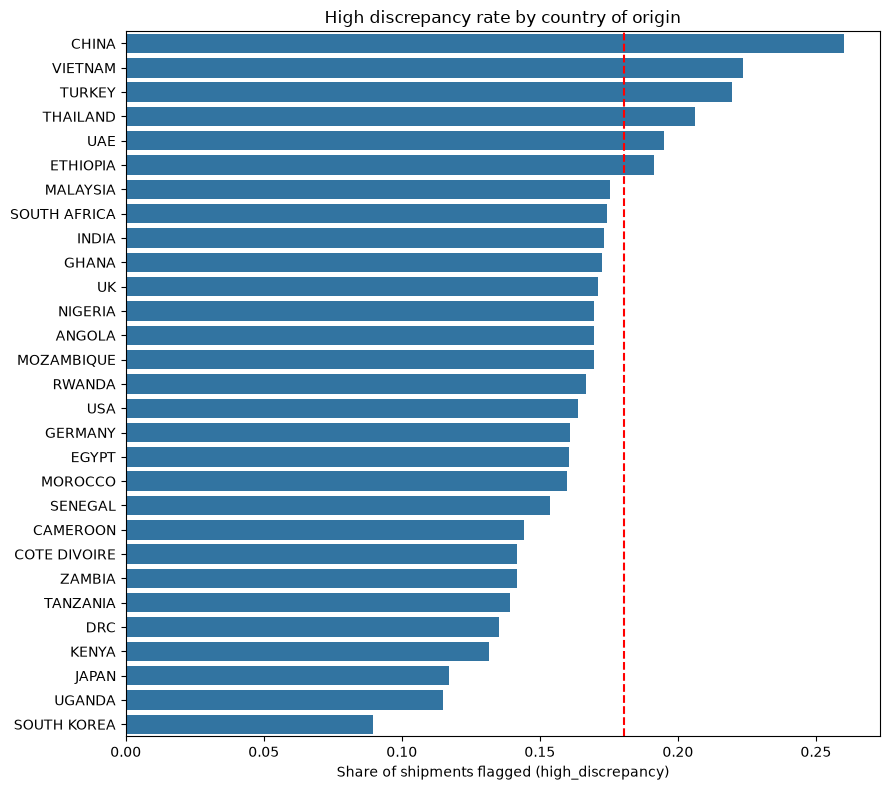

In [16]:
disc_broker = plot_rate("broker", "high_discrepancy", "High discrepancy rate by broker", "05a_discrepancy_by_broker.png")
disc_section = plot_rate("hs_section_name", "high_discrepancy", "High discrepancy rate by HS section", "05b_discrepancy_by_section.png")
disc_supplier = plot_rate("supplier", "high_discrepancy", "High discrepancy rate by supplier", "05c_discrepancy_by_supplier.png", height=6)
disc_origin = plot_rate("country_origin", "high_discrepancy", "High discrepancy rate by country of origin", "05d_discrepancy_by_origin.png", height=8)

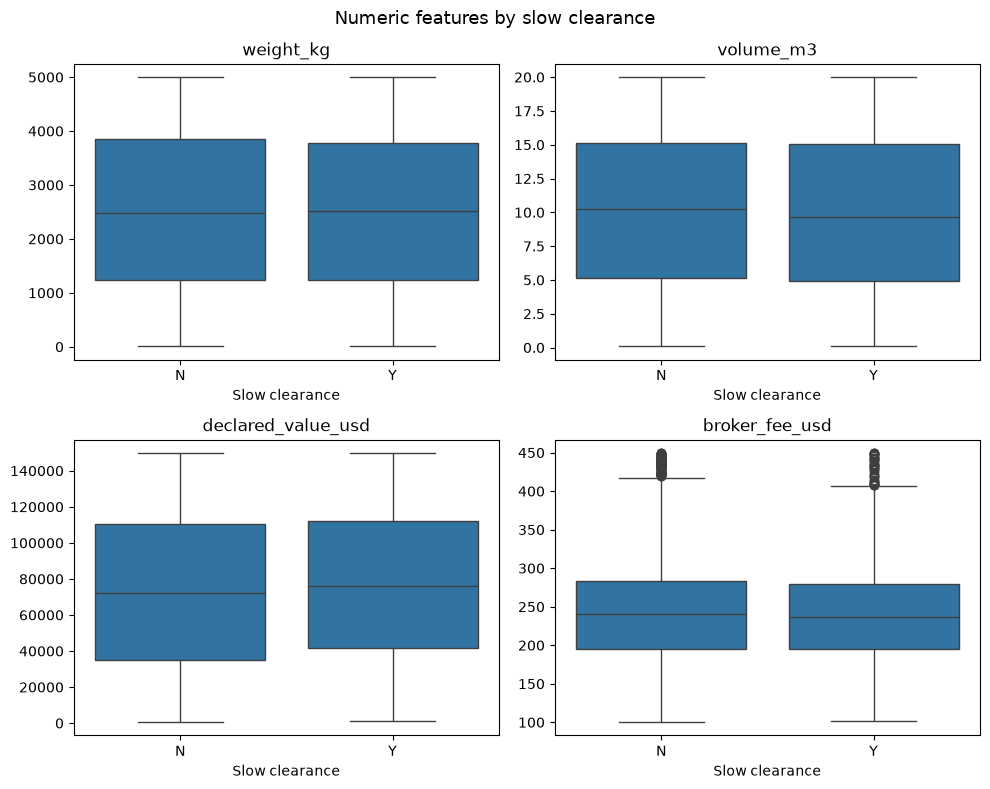

In [17]:
# CHART 6: Numeric features by slow clearance
# Question: do weight, volume, declared value or broker fee differ between slow and not-slow shipments?
# Method: loop draws one boxplot per column in a 2 x 2 grid

numeric_cols = ["weight_kg", "volume_m3", "declared_value_usd", "broker_fee_usd"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df, x="slow_clearance", y=col, order=["N", "Y"], ax=ax, color="tab:blue")
    ax.set_title(col)
    ax.set_xlabel("Slow clearance")
    ax.set_ylabel("")

fig.suptitle("Numeric features by slow clearance", fontsize=13)
plt.tight_layout()
plt.savefig("images/06_numeric_by_slow.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
df.groupby("slow_clearance")[numeric_cols].agg(["median", "mean"]).round(1)

weight_kg         volume_m3       declared_value_usd           \
                  median    mean    median  mean             median     mean   
slow_clearance                                                                 
N                 2478.1  2509.7      10.2  10.2            72416.9  72783.9   
Y                 2515.9  2506.9       9.6   9.9            75896.9  76628.6   

               broker_fee_usd         
                       median   mean  
slow_clearance                        
N                       240.2  247.0  
Y                       236.9  243.9

In [19]:
top = df["declared_value_usd"] > df["declared_value_usd"].quantile(0.9)
df.groupby(top)["slow_clearance"].apply(lambda s: (s == "Y").mean())

declared_value_usd
False    0.258019
True     0.284211
Name: slow_clearance, dtype: float64

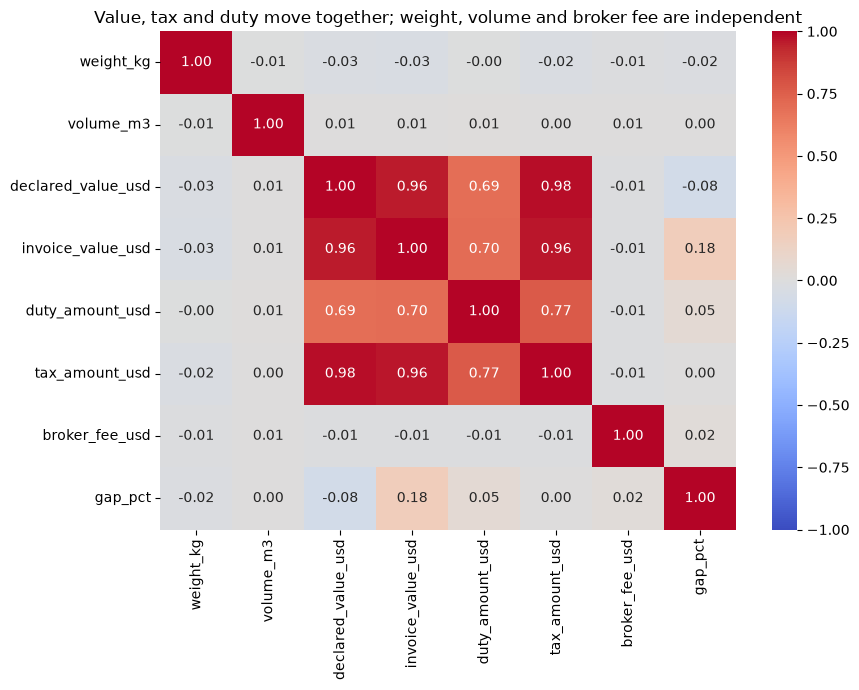

In [20]:
# CHART 7: Correlation heatmap
# Question: which numeric columns carry the same information, and which are independent?
# Method: correlation matrix of numeric columns; gap_pct included for exploration only 
# (part of the target definition)

corr_cols = ["weight_kg", "volume_m3", "declared_value_usd", "invoice_value_usd",
             "duty_amount_usd", "tax_amount_usd", "broker_fee_usd", "gap_pct"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)

plt.title("Value, tax and duty move together; weight, volume and broker fee are independent")
plt.tight_layout()
plt.savefig("images/07_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

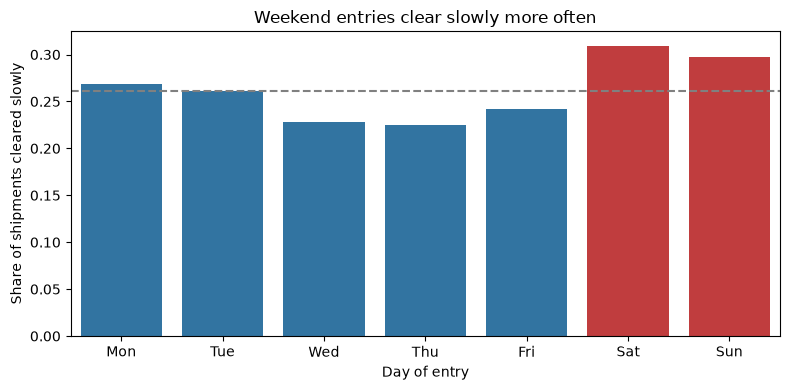

In [21]:
# CHART 8: Slow rate by day of entry
# Question: does the weekend effect hold on both days, and does any weekday stand out?
# Method: slow rate per day of week; weekend bars in red, grey line = overall rate (26.1%)

day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

day_rates = (
    df.assign(flag=df["slow_clearance"] == "Y")
      .groupby("entry_day_of_week")["flag"]
      .mean()
      .reset_index()
)
day_rates["day"] = day_rates["entry_day_of_week"].map(lambda i: day_names[i])
day_rates["is_weekend"] = day_rates["entry_day_of_week"] >= 5

plt.figure(figsize=(8, 4))
sns.barplot(data=day_rates, x="day", y="flag", hue="is_weekend",
            palette={False: "tab:blue", True: "tab:red"}, legend=False)
plt.axhline(0.261, linestyle="--", color="grey")

plt.title("Weekend entries clear slowly more often")
plt.xlabel("Day of entry")
plt.ylabel("Share of shipments cleared slowly")

plt.tight_layout()
plt.savefig("images/08_slow_rate_by_day.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
hours = (df["release_date"] - df["entry_date"]).dt.total_seconds() / 3600
hours.groupby(df["entry_day_of_week"]).median().round(1)

entry_day_of_week
0    32.5
1    33.0
2    29.5
3    31.0
4    33.0
5    34.0
6    34.0
dtype: float64